# Access OceanSODA-ETHZ

This database contains the two Ocean-Soda datasets - v1 and v2, which are different products on different temporal scales and grids.

1. ocean-soda.zarr - a global monthly gridded dataset of the surface ocean carbonate system for seasonal to decadal studies of ocean acidification. The result of ocean soda v1.
2. OceanSODA_ETHZv2.r2026.GCB-fgco2-1982_2025-pyramid.zarr - which is a geozarr of a global 8day gridded dataset of the surface ocean carbonate system . The result of ocean soda v2.
3. OceanSoda v2 (2025) an older version of the above dataset.

    * Original Data Source: https://doi.org/10.25921/m5wx-ja34
    * Reference:  https://doi.org/10.25921/m5wx-ja34
    * OSC entry: https://opensciencedata.esa.int/products/ocean-soda-ethz/collection
    * License: CC-BY-NC-SA-4.0

## OceanSoda v2

In [2]:
import xarray as xr

zarr_href = 'https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/ocean-soda/OceanSODA_ETHZv2.r2026.GCB-fgco2-1982_2025-pyramid.zarr'

In [3]:
ds = xr.open_zarr(zarr_href, group='0') # read the first group, this is the lowest resolution available data
ds

<xarray.Dataset> Size: 50GB
Dimensions:      (time: 2024, lat: 720, lon: 1440, region: 4)
Coordinates:
  * time         (time) datetime64[ns] 16kB 1982-01-05 1982-01-13 ... 2025-12-29
  * lat          (lat) float64 6kB 89.88 89.62 89.38 ... -89.38 -89.62 -89.88
  * lon          (lon) float64 12kB -179.9 -179.6 -179.4 ... 179.4 179.6 179.9
  * region       (region) object 32B 'global' 'north' 'tropics' 'south'
    spatial_ref  int64 8B ...
Data variables:
    alpha        (time, lat, lon) float32 8GB dask.array<chunksize=(1, 512, 512), meta=np.ndarray>
    area         (lat, lon) float32 4MB dask.array<chunksize=(512, 512), meta=np.ndarray>
    fco2atm      (time, lat, lon) float32 8GB dask.array<chunksize=(1, 512, 512), meta=np.ndarray>
    fgco2        (time, lat, lon) float32 8GB dask.array<chunksize=(1, 512, 512), meta=np.ndarray>
    kw           (time, lat, lon) float32 8GB dask.array<chunksize=(1, 512, 512), meta=np.ndarray>
    mask_sfc     (lat, lon) bool 1MB dask.array<chunksize=(512, 512), meta=np.ndarray>
    sfco2        (time, lat, lon) float32 8GB dask.array<chunksize=(1, 512, 512), meta=np.ndarray>
    tos          (time, lat, lon) float32 8GB dask.array<chunksize=(1, 512, 512), meta=np.ndarray>
Attributes:
    spatial:dimensions:      ['lat', 'lon']
    spatial:bbox:            [-180.0, -90.0, 180.0, 90.0]
    spatial:transform_type:  affine
    spatial:transform:       [0.25, 0.0, -180.0, 0.0, -0.25, 90.0]
    spatial:shape:           [720, 1440]
    spatial:registration:    pixel
    proj:code:               EPSG:4326
    proj:wkt2:               GEOGCRS["WGS 84",ENSEMBLE["World Geodetic System...
    zarr_conventions:        [{'uuid': '689b58e2-cf7b-45e0-9fff-9cfc0883d6b4'...

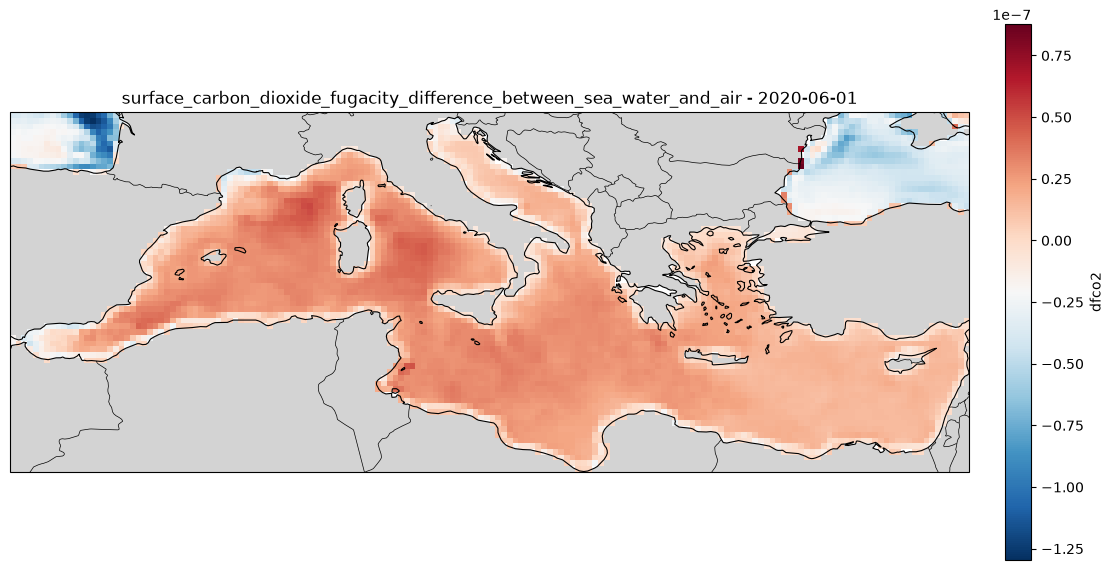

In [9]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np

# Choose date
date = "2020-06-01"

# Select FSLE for that date
pp = ds["fgco2"].sel( lon=slice(-6.062, 36.06), lat=slice( 45.98, 30.27,), drop=True)
pp = pp.sel(time=np.datetime64(date), drop=True, method='nearest')

# 2-D coordinates
lon = pp["lon"]
lat = pp["lat"]

# Create map
fig = plt.figure(figsize=(12, 7))

ax = plt.axes(projection=ccrs.PlateCarree())

# Plot FSLE
pcm = ax.pcolormesh(
    lon,
    lat,
    pp,
    transform=ccrs.PlateCarree(),
    shading="auto",
    cmap="RdBu_r"
)

# Basemap features
ax.add_feature(cfeature.LAND, facecolor="lightgray")
ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linewidth=0.5)


# Colourbar
cbar = plt.colorbar(
    pcm,
    ax=ax,
    orientation="vertical",
    pad=0.03,
    shrink=0.8
)
cbar.set_label("dfco2")

ax.set_title(f"surface_carbon_dioxide_fugacity_difference_between_sea_water_and_air - {date}")

plt.tight_layout()
plt.show()

## OceanSODA v1

In [8]:
data_href = 'https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/ocean-soda/ocean-soda.zarr'

In [9]:
ds = xr.open_zarr(data_href, chunks={})
ds

<xarray.Dataset> Size: 3GB
Dimensions:          (time: 516, lat: 180, lon: 360)
Coordinates:
  * time             (time) datetime64[ns] 4kB 1982-01-15 ... 2024-12-15
    year             (time) int64 4kB dask.array<chunksize=(516,), meta=np.ndarray>
  * lat              (lat) float64 1kB -89.5 -88.5 -87.5 ... 87.5 88.5 89.5
  * lon              (lon) float64 3kB -179.5 -178.5 -177.5 ... 178.5 179.5
Data variables: (12/21)
    co2              (time, lat, lon) float32 134MB dask.array<chunksize=(516, 45, 45), meta=np.ndarray>
    co3              (time, lat, lon) float32 134MB dask.array<chunksize=(516, 45, 45), meta=np.ndarray>
    dic              (time, lat, lon) float32 134MB dask.array<chunksize=(516, 45, 45), meta=np.ndarray>
    dic_uncert       (time, lat, lon) float32 134MB dask.array<chunksize=(516, 45, 45), meta=np.ndarray>
    hco3             (time, lat, lon) float32 134MB dask.array<chunksize=(516, 45, 45), meta=np.ndarray>
    omega_ar         (time, lat, lon) float32 134MB dask.array<chunksize=(516, 45, 45), meta=np.ndarray>
    ...               ...
    sfco2_uncert     (time, lat, lon) float32 134MB dask.array<chunksize=(516, 45, 45), meta=np.ndarray>
    spco2            (time, lat, lon) float32 134MB dask.array<chunksize=(516, 45, 45), meta=np.ndarray>
    spco2_uncert     (time, lat, lon) float32 134MB dask.array<chunksize=(516, 45, 45), meta=np.ndarray>
    talk             (time, lat, lon) float32 134MB dask.array<chunksize=(516, 45, 45), meta=np.ndarray>
    talk_uncert      (time, lat, lon) float32 134MB dask.array<chunksize=(516, 45, 45), meta=np.ndarray>
    temperature      (time, lat, lon) float32 134MB dask.array<chunksize=(516, 45, 45), meta=np.ndarray>
Attributes:
    contact:      gregorl@ethz.ch
    author:       Luke Gregor
    institution:  ETH Zuerich
    version:      v2025.OCADS
    date:         2025-10-09
    description:  talk and pco2 (more accurately fco2) are estimated with two...
    changelog:    v2021d: Extended from 1982-2020; Now using: OISSTv2.1 for S...
    reference:    Gregor, L. and Gruber, N.: OceanSODA-ETHZ: A global gridded...
    source:       https://doi.org/10.25921/m5wx-ja34
    product:      OSETHZ-v2025.OCADS

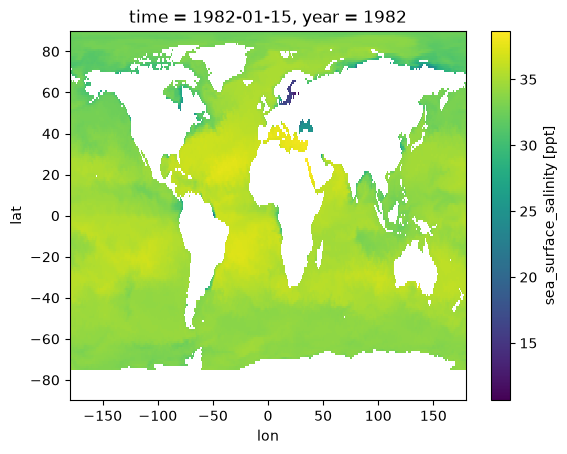

In [10]:
ds.salinity.isel(time=0).plot()

### OceanSODA v2 - old

In [10]:
zarr_href1 = 'https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/ocean-soda/dfco2.zarr'
zarr_href2 = 'https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/ocean-soda/fgco2.zarr'
zarr_href3 = 'https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/ocean-soda/fgco2CT.zarr'
zarr_href4 = 'https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/ocean-soda/ice.zarr'
zarr_href5 = 'https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/ocean-soda/kw.zarr'
zarr_href6 = 'https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/ocean-soda/sfco2.zarr'
zarr_href7 = 'https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/ocean-soda/sfco2_uncert.zarr'
zarr_href8 = 'https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/ocean-soda/sol.zarr'
zarr_href9 = 'https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/ocean-soda/temperature.zarr'


In [11]:
ds = xr.open_zarr(zarr_href1)
ds

<xarray.Dataset> Size: 8GB
Dimensions:  (time: 1886, lat: 720, lon: 1440)
Coordinates:
  * time     (time) datetime64[ns] 15kB 1982-01-04 1982-01-12 ... 2022-12-30
  * lat      (lat) float64 6kB -89.88 -89.62 -89.38 -89.12 ... 89.38 89.62 89.88
  * lon      (lon) float64 12kB -179.9 -179.6 -179.4 ... 179.4 179.6 179.9
Data variables:
    dfco2    (time, lat, lon) float32 8GB dask.array<chunksize=(24, 720, 1440), meta=np.ndarray>
Attributes: (12/14)
    contact:                   gregorl@ethz.ch
    affiliation:               ETH Zuerich
    product_name:              OceanSODA-ETHZ-HR
    product_version:           v2023.01
    project:                   ESA-OceanHealth-OceanAcidification
    product_details:           Fugacity of CO2 (fCO2) and total alkalinity ar...
    ...                        ...
    geospatial_min_latitude:   -89.875
    geospatial_max_latitude:   89.875
    geospatial_min_longitude:  -179.875
    geospatial_max_longitude:  179.875
    time_coverage_start:       1982-01-01T00:00:00
    time_coverage_end:         1982-01-08T23:59:59

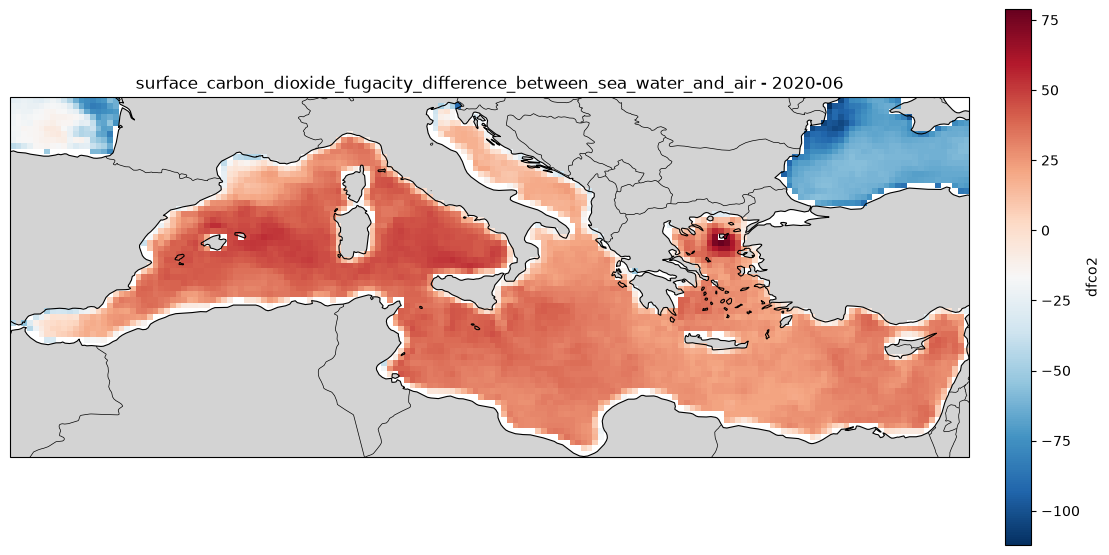

In [13]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np

# Choose date
date = "2020-06"

# Select FSLE for that date
pp = ds["dfco2"].sel( lon=slice(-6.062, 36.06), lat=slice(30.27, 45.98), drop=True)
pp = pp.sel(time=np.datetime64(date), drop=True, method='nearest')

# 2-D coordinates
lon = pp["lon"]
lat = pp["lat"]

# Create map
fig = plt.figure(figsize=(12, 7))

ax = plt.axes(projection=ccrs.PlateCarree())

# Plot FSLE
pcm = ax.pcolormesh(
    lon,
    lat,
    pp,
    transform=ccrs.PlateCarree(),
    shading="auto",
    cmap="RdBu_r"
)

# Basemap features
ax.add_feature(cfeature.LAND, facecolor="lightgray")
ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linewidth=0.5)


# Colourbar
cbar = plt.colorbar(
    pcm,
    ax=ax,
    orientation="vertical",
    pad=0.03,
    shrink=0.8
)
cbar.set_label("dfco2")

ax.set_title(f"surface_carbon_dioxide_fugacity_difference_between_sea_water_and_air - {date}")

plt.tight_layout()
plt.show()